In [1]:
#THIS NOTEBOOK TRAINS A MULTI-TASK MODEL JOINTLY PREDICTING Tm AND dHfus, USING THE PRE-MATCHED DATASET
from chemprop_utils import load_and_clean_data, build_splits, build_and_train_multitask_mpnn, predict_multitask
from pathlib import Path
import pandas as pd
import numpy as np
from lightning import pytorch as pl

pl.seed_everything(0, workers=True)

from pathlib import Path
print(Path.cwd())



input_path = Path("RAW DATA") / "matched_T_and_H.csv"
smiles_column = "smiles"
target_columns = ["Tm[K]", "dHfus [kcal/mol]"]   #VERIFY EXACT NAMES AGAINST df.columns FIRST

df_clean, all_data, mols = load_and_clean_data(input_path, smiles_column, target_columns)
splits = build_splits(all_data, mols, split_types=("scaffold_balanced",))

result_multitask = build_and_train_multitask_mpnn(
    splits["scaffold_balanced"]["train"],
    splits["scaffold_balanced"]["val"],
    splits["scaffold_balanced"]["test"],
    task_names=["Tm", "dHfus"],
    dropout=0.4,
    run_name="multitask_Tm_dHfus",
)

test_metrics = result_multitask["test_results"][0]
print("Multi-task test metrics:", test_metrics)   #INSPECT ACTUAL KEYS — MULTI-TASK METRIC NAMING MAY DIFFER FROM SINGLE-TASK

task_predictions = predict_multitask(result_multitask, run_name="multitask")
for task_name, df in task_predictions.items():
    mae = df["abs_error"].mean()
    rmse = np.sqrt((df["abs_error"] ** 2).mean())
    print(f"{task_name}: MAE={mae:.3f}, RMSE={rmse:.3f}")
    df.to_csv(f"multitask_{task_name}_predictions.csv", index=False)



Seed set to 0


c:\Users\Jaco Olivier\Downloads\SCRIPSIE\Code Related\Implement
Found 713 rows in 'Tm[K]' with comma-separated multi-value strings — averaging them
Loaded 744 rows, dropped 0 with missing/invalid target, smiles, or stereo issues, 744 remain


The return type of make_split_indices has changed in v2.1 - see help(make_split_indices)
c:\Users\Jaco Olivier\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\astartes\samplers\extrapolation\scaffold.py:48: NoMatchingScaffold: No matching scaffold was found for the 329 molecules corresponding to indices {0, 1, 8, 9, 10, 11, 14, 19, 22, 26, 28, 30, 31, 32, 33, 37, 38, 45, 46, 47, 48, 52, 53, 55, 58, 59, 63, 64, 67, 70, 72, 77, 79, 82, 83, 87, 90, 91, 94, 95, 97, 99, 101, 102, 103, 104, 109, 111, 112, 113, 114, 116, 118, 119, 121, 122, 123, 126, 127, 128, 129, 130, 131, 134, 135, 137, 140, 142, 143, 144, 145, 146, 149, 150, 152, 154, 155, 156, 157, 158, 159, 161, 165, 167, 169, 173, 174, 179, 180, 182, 183, 185, 187, 188, 194, 196, 197, 204, 207, 211, 218, 219, 221, 222, 225, 226, 229, 235, 236, 237, 238, 241, 245, 248, 252, 253, 256, 258, 262, 264, 267, 269, 272, 274, 277, 284, 285, 288, 290, 292, 293, 296, 298, 299, 300, 304, 306, 309, 310, 314, 319, 321, 326, 327, 331, 336, 

scaffold_balanced: train=596, val=74, test=74


c:\Users\Jaco Olivier\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
c:\Users\Jaco Olivier\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.
c:\Users\Jaco Olivier\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightning\pytorch\loops\fit_loop.py:317: The number of training batches (10) is smaller than the logging interval Trainer(log_every_n_steps=50). Set a lower value for log_every_n_steps if you want to see logs for the training epoch.


┏━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name            ┃ Type               ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ message_passing │ BondMessagePassing │  227 K │ train │     0 │
│ 1 │ agg             │ MeanAggregation    │      0 │ train │     0 │
│ 2 │ bn              │ BatchNorm1d        │    600 │ train │     0 │
│ 3 │ predictor       │ RegressionFFN      │ 90.9 K │ train │     0 │
│ 4 │ X_d_transform   │ Identity           │      0 │ train │     0 │
│ 5 │ metrics         │ ModuleList         │      0 │ train │     0 │
└───┴─────────────────┴────────────────────┴────────┴───────┴───────┘

... (7 outputs left out)

Output()

Multi-task test metrics: {'test/rmse': 49.886962890625, 'test/mae': 27.921815872192383}


c:\Users\Jaco Olivier\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.


Tm: MAE=53.744, RMSE=70.491
dHfus: MAE=2.099, RMSE=2.903


In [2]:
#EXPERIMENT 2: FULL POOLED MULTI-TASK — ALL dHfus MOLECULES + 10K Tm MOLECULES, NO OVERLAP REQUIRED
from chemprop_utils import load_and_pool_multitask_data, build_splits, build_and_train_multitask_mpnn, predict_multitask

df_pooled, pooled_data, pooled_mols = load_and_pool_multitask_data(
    dhfus_path=Path("RAW DATA") / "dHfus_DB.csv",
    tm_path=Path("RAW DATA") / "Tmp_DB.csv",
    smiles_column="smiles",
    dhfus_target_col="dHfus [kcal/mol]",
    tm_target_col="Tm[K]",
    tm_sample_size=10000,
    seed=0,
)

pooled_splits = build_splits(pooled_data, pooled_mols, split_types=("scaffold_balanced",))

result_pooled = build_and_train_multitask_mpnn(
    pooled_splits["scaffold_balanced"]["train"],
    pooled_splits["scaffold_balanced"]["val"],
    pooled_splits["scaffold_balanced"]["test"],
    task_names=["Tm", "dHfus"],
    dropout=0.4,
    run_name="multitask_pooled",
)

pooled_predictions = predict_multitask(result_pooled, run_name="multitask_pooled")
for task_name, df in pooled_predictions.items():
    #DROP NaN ROWS BEFORE COMPUTING METRICS — TEST SET MAY CONTAIN MOLECULES MISSING ONE TASK'S TRUE LABEL
    df_valid = df.dropna(subset=["y_true"])
    mae = df_valid["abs_error"].mean()
    rmse = np.sqrt((df_valid["abs_error"] ** 2).mean())
    print(f"Pooled multi-task — {task_name}: MAE={mae:.3f}, RMSE={rmse:.3f} (n={len(df_valid)})")
    df.to_csv(f"multitask_pooled_{task_name}_predictions.csv", index=False)


Found 20624 Tm rows with comma-separated multi-value strings — averaging them
Subsampled Tm dataset to 10000 molecules
Pooled dataset: 15151 total molecules (4657 with dHfus, 10000 with Tm, 31 with both)


[08:49:47] Explicit valence for atom # 2 S, 6, is greater than permitted
[08:49:47] WARNING: not removing hydrogen atom without neighbors
[08:49:47] WARNING: not removing hydrogen atom without neighbors
[08:49:47] WARNING: not removing hydrogen atom without neighbors
[08:49:47] WARNING: not removing hydrogen atom without neighbors
[08:49:47] WARNING: not removing hydrogen atom without neighbors
[08:49:48] WARNING: not removing hydrogen atom without neighbors
[08:49:48] WARNING: not removing hydrogen atom without neighbors
[08:49:49] Unusual charge on atom 6 number of radical electrons set to zero


After cleaning: 14625 molecules remain


[08:49:51] WARNING: not removing hydrogen atom without neighbors
[08:49:51] WARNING: not removing hydrogen atom without neighbors
[08:49:51] WARNING: not removing hydrogen atom without neighbors
[08:49:51] WARNING: not removing hydrogen atom without neighbors
[08:49:51] WARNING: not removing hydrogen atom without neighbors
[08:49:52] WARNING: not removing hydrogen atom without neighbors
[08:49:52] WARNING: not removing hydrogen atom without neighbors
[08:49:52] Unusual charge on atom 6 number of radical electrons set to zero
The return type of make_split_indices has changed in v2.1 - see help(make_split_indices)
c:\Users\Jaco Olivier\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\astartes\samplers\extrapolation\scaffold.py:48: NoMatchingScaffold: No matching scaffold was found for the 1546 molecules corresponding to indices {1, 3, 4, 5, 6, 7, 8, 9, 10, 11, 15, 16, 17, 89, 90, 91, 93, 96, 97, 106, 107, 147, 148, 149, 151, 152, 155, 169, 216, 217, 218, 219, 221, 223, 224, 225,

scaffold_balanced: train=11701, val=1462, test=1462


c:\Users\Jaco Olivier\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
c:\Users\Jaco Olivier\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.


... (7 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         test/mae          │    26.527482986450195     │
│         test/rmse         │    37.047142028808594     │
└───────────────────────────┴───────────────────────────┘

Output()

c:\Users\Jaco Olivier\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.


Pooled multi-task — Tm: MAE=32.730, RMSE=41.460 (n=1167)
Pooled multi-task — dHfus: MAE=2.154, RMSE=3.362 (n=297)


 Task                                Model       MAE      RMSE
   Tm                 Single-task baseline 36.490997 48.657012
   Tm     Multi-task (overlap only, n=596) 53.744451 70.491075
   Tm Multi-task (pooled, no overlap req.) 32.730422 41.459744
dHfus                 Single-task baseline  1.464109  2.014384
dHfus     Multi-task (overlap only, n=596)  2.099173  2.902844
dHfus Multi-task (pooled, no overlap req.)  2.154307  3.362345


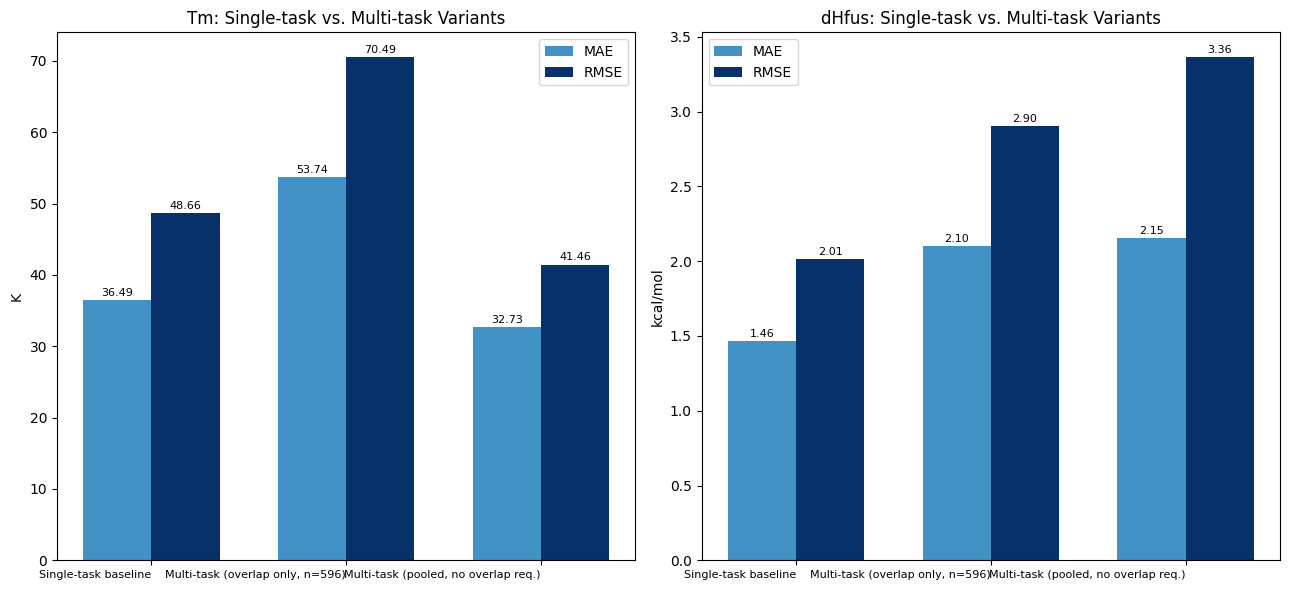

In [3]:



import matplotlib.pyplot as plt

#THREE-WAY COMPARISON: SINGLE-TASK BASELINE vs. OVERLAP-ONLY MULTI-TASK (596 molecules) vs. FULL POOLED MULTI-TASK
dhfus_single = pd.read_csv("dHfus_baseline_predictions.csv")
tm_single = pd.read_csv("Tm_baseline_predictions.csv")

#POOLED RESULTS — DROP NaN ROWS BEFORE COMPUTING METRICS, SAME AS THE PRINTED OUTPUT DID
pooled_tm_valid = pooled_predictions["Tm"].dropna(subset=["y_true"])
pooled_dhfus_valid = pooled_predictions["dHfus"].dropna(subset=["y_true"])

comparison_rows = [
    {"Task": "Tm", "Model": "Single-task baseline",
     "MAE": tm_single["abs_error"].mean(), "RMSE": np.sqrt((tm_single["abs_error"] ** 2).mean())},
    {"Task": "Tm", "Model": "Multi-task (overlap only, n=596)",
     "MAE": task_predictions["Tm"]["abs_error"].mean(), "RMSE": np.sqrt((task_predictions["Tm"]["abs_error"] ** 2).mean())},
    {"Task": "Tm", "Model": "Multi-task (pooled, no overlap req.)",
     "MAE": pooled_tm_valid["abs_error"].mean(), "RMSE": np.sqrt((pooled_tm_valid["abs_error"] ** 2).mean())},

    {"Task": "dHfus", "Model": "Single-task baseline",
     "MAE": dhfus_single["abs_error"].mean(), "RMSE": np.sqrt((dhfus_single["abs_error"] ** 2).mean())},
    {"Task": "dHfus", "Model": "Multi-task (overlap only, n=596)",
     "MAE": task_predictions["dHfus"]["abs_error"].mean(), "RMSE": np.sqrt((task_predictions["dHfus"]["abs_error"] ** 2).mean())},
    {"Task": "dHfus", "Model": "Multi-task (pooled, no overlap req.)",
     "MAE": pooled_dhfus_valid["abs_error"].mean(), "RMSE": np.sqrt((pooled_dhfus_valid["abs_error"] ** 2).mean())},
]
multitask_comparison_df = pd.DataFrame(comparison_rows)
print(multitask_comparison_df.to_string(index=False))
multitask_comparison_df.to_csv("multitask_vs_single_comparison.csv", index=False)


#BAR CHART — THREE BARS PER TASK NOW INSTEAD OF TWO
fig, axes = plt.subplots(1, 2, figsize=(13, 6))

for ax, task in zip(axes, ["Tm", "dHfus"]):
    subset = multitask_comparison_df[multitask_comparison_df["Task"] == task]
    x = np.arange(len(subset))
    width = 0.35

    bars_mae = ax.bar(x - width/2, subset["MAE"], width, label="MAE", color="#4292c6")
    bars_rmse = ax.bar(x + width/2, subset["RMSE"], width, label="RMSE", color="#08306b")

    for bars in [bars_mae, bars_rmse]:
        for bar in bars:
            height = bar.get_height()
            ax.annotate(f"{height:.2f}", xy=(bar.get_x() + bar.get_width() / 2, height),
                        xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8)

    ax.set_xticks(x)
    ax.set_xticklabels(subset["Model"], rotation=0, ha="right", fontsize=8)
    ax.set_ylabel("K" if task == "Tm" else "kcal/mol")
    ax.set_title(f"{task}: Single-task vs. Multi-task Variants")
    ax.legend()

plt.tight_layout()
plt.savefig("plots_multitask_three_way_comparison.png", dpi=150)
plt.show()